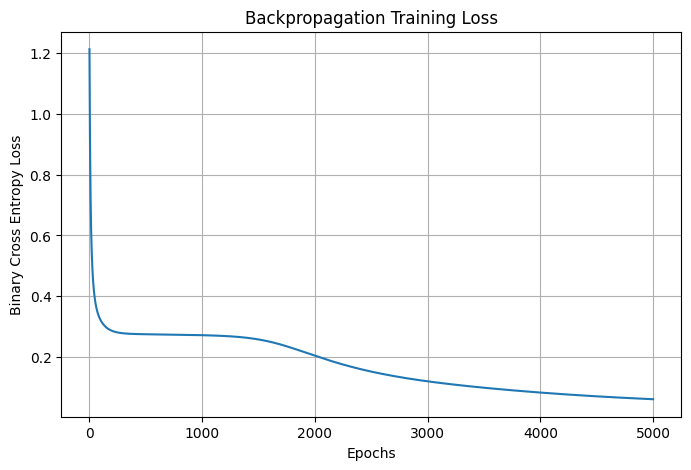

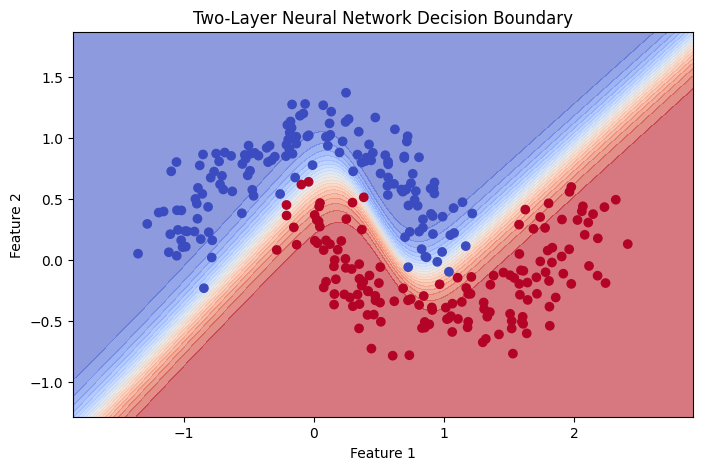

Analytical Gradient: 0.0013783763536569854
Numerical Gradient: 0.001378376419253202
Gradient Difference: 6.559621660955084e-11
Final Training Accuracy: 98.0 %


In [7]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

np.random.seed(42)

# 1. Generate two-moons dataset
X, y = make_moons(n_samples=300, noise=0.15, random_state=42)
y = y.reshape(-1, 1)

# Initialise weights
W1 = np.random.randn(2, 8) * 0.5
b1 = np.zeros((1, 8))
W2 = np.random.randn(8, 1) * 0.5
b2 = np.zeros((1, 1))

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

# 2. Forward propagation
def forward(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    return z1, a1, a2

# 3. Backpropagation
lr = 0.1
losses = []

for epoch in range(5000):
    z1, a1, a2 = forward(X)

    loss = -np.mean(
        y*np.log(a2+1e-8) +
        (1-y)*np.log(1-a2+1e-8)
    )
    losses.append(loss)

    dz2 = (a2-y) / len(X)
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    da1 = dz2 @ W2.T
    dz1 = da1 * (1-a1**2)

    dW1 = X.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    W2 -= lr*dW2
    b2 -= lr*db2
    W1 -= lr*dW1
    b1 -= lr*db1

# 4. Plot loss
plt.figure(figsize=(8, 5))
plt.plot(losses)
plt.xlabel("Epochs")
plt.ylabel("Binary Cross Entropy Loss")
plt.title("Backpropagation Training Loss")
plt.grid()
plt.show()

# 5. Decision boundary
xx, yy = np.meshgrid(
    np.linspace(X[:,0].min()-0.5, X[:,0].max()+0.5, 200),
    np.linspace(X[:,1].min()-0.5, X[:,1].max()+0.5, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
_, _, predictions = forward(grid)

plt.figure(figsize=(8, 5))
plt.contourf(
    xx, yy, predictions.reshape(xx.shape),
    levels=20, cmap="coolwarm", alpha=0.6
)
plt.scatter(X[:,0], X[:,1], c=y.ravel(), cmap="coolwarm")
plt.title("Two-Layer Neural Network Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 6. Numerical gradient verification for one weight
z1, a1, a2 = forward(X)
dz2 = (a2-y)/len(X)
analytic_grad = (a1.T @ dz2)[0, 0]

epsilon = 1e-5
original = W2[0, 0]

W2[0, 0] = original + epsilon
_, _, p1 = forward(X)
loss1 = -np.mean(y*np.log(p1+1e-8)+(1-y)*np.log(1-p1+1e-8))

W2[0, 0] = original - epsilon
_, _, p2 = forward(X)
loss2 = -np.mean(y*np.log(p2+1e-8)+(1-y)*np.log(1-p2+1e-8))

W2[0, 0] = original

numerical_grad = (loss1-loss2)/(2*epsilon)

print("Analytical Gradient:", analytic_grad)
print("Numerical Gradient:", numerical_grad)
print("Gradient Difference:", abs(analytic_grad-numerical_grad))
print("Final Training Accuracy:",
      np.mean((forward(X)[2] >= 0.5) == y)*100, "%")
